# TDE 03 — Baseline: Predição do Valor de Imóveis em São Paulo

**Integrantes do grupo:**

| Nome | Matrícula |
|---|---|
| Thalys Eduardo Ferreira Cazuza | 20241180148 |
| Arthur Rodrigues de Carvalho | 20241130037 |
| Ramon Porfírio Macedo | 20241130023 |

## Objetivo desta etapa

No TDE 01 o grupo definiu o projeto: prever o **preço de venda** e o **preço de aluguel** de imóveis
em São Paulo a partir das características do imóvel e da sua localização.

Nesta etapa montamos o **baseline** do projeto: treinamos algoritmos vistos em sala **sem nenhuma
otimização** e medimos o desempenho com as métricas de avaliação de regressão. Esses resultados são o
**ponto de comparação** para a próxima etapa, quando os modelos serão otimizados.

**Algoritmos (vistos em sala):**
1. **Regressão Linear**
2. **Regressão Polinomial (grau 2)**

**Métricas de avaliação:** MAE, MSE, RMSE e R².

**O que "sem otimizações" quer dizer aqui:**
- parâmetros padrão do scikit-learn (o grau 2 é o menor grau polinomial depois do linear, escolhido sem testar outros);
- sem regularização (Ridge/Lasso), sem normalização das variáveis, sem transformar o preço e sem busca de hiperparâmetros;
- as mesmas variáveis do TDE 01.

## Dataset

- Fonte: https://www.kaggle.com/datasets/argonalyst/sao-paulo-real-estate-sale-rent-april-2019
- Arquivo: `sao-paulo-properties-april-2019.csv` (baixe no Kaggle e coloque na mesma pasta deste notebook;
  no Google Colab, faça o upload do arquivo antes de rodar).

## 1. Bibliotecas

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Mostra os números das tabelas com separador de milhar e 2 casas decimais
pd.options.display.float_format = "{:,.2f}".format

## 2. Carregando os dados

In [2]:
dados = pd.read_csv("sao-paulo-properties-april-2019.csv")
print("Linhas e colunas:", dados.shape)
dados.head()

Linhas e colunas: (13640, 16)


,Price,Condo,Size,Rooms,Toilets,Suites,Parking,Elevator,Furnished,Swimming Pool,New,District,Negotiation Type,Property Type,Latitude,Longitude
0,930,220,47,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.54,-46.48
1,1000,148,45,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.55,-46.48
2,1000,100,48,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.54,-46.49
3,1000,200,48,2,2,1,1,0,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.55,-46.48
4,1300,410,55,2,2,1,1,1,0,0,0,Artur Alvim/São Paulo,rent,apartment,-23.53,-46.48


In [3]:
# Valores faltando em cada coluna
dados.isnull().sum()

Price               0
Condo               0
Size                0
Rooms               0
Toilets             0
Suites              0
Parking             0
Elevator            0
Furnished           0
Swimming Pool       0
New                 0
District            0
Negotiation Type    0
Property Type       0
Latitude            0
Longitude           0
dtype: int64

## 3. Preparação dos dados

Usamos as mesmas variáveis do TDE 01. A limpeza é só o mínimo necessário:

- remover linhas com valores faltando (o dataset não tem nenhuma, mas deixamos a verificação);
- remover imóveis com latitude/longitude fora da cidade de São Paulo. Ao preparar o baseline encontramos
  **986 imóveis (7% do dataset)** com coordenada errada: 881 com latitude e longitude iguais a 0, 17 com as duas
  trocadas e 88 apontando para fora da cidade. Isso é importante principalmente para a regressão polinomial, que
  eleva as variáveis ao quadrado: uma coordenada errada vira um valor enorme e estraga as previsões.

Assim como no TDE 01, treinamos **um modelo para venda e outro para aluguel**, porque os preços estão em escalas
completamente diferentes.

In [4]:
colunas_features = ["Condo", "Size", "Rooms", "Toilets", "Suites", "Parking",
                    "Elevator", "Furnished", "Swimming Pool", "New",
                    "Latitude", "Longitude"]

# Remove linhas com valores faltando nas colunas que vamos usar
dados = dados.dropna(subset=colunas_features + ["Price"])

# Remove imóveis com coordenadas fora da cidade de São Paulo
dentro_de_sp = dados["Latitude"].between(-24.1, -23.3) & dados["Longitude"].between(-47.0, -46.3)
print("Imóveis removidos por coordenada fora de SP:", (~dentro_de_sp).sum())
dados = dados[dentro_de_sp]

# Separa venda e aluguel
dados_venda = dados[dados["Negotiation Type"] == "sale"]
dados_aluguel = dados[dados["Negotiation Type"] == "rent"]

print("Imóveis de venda:", len(dados_venda))
print("Imóveis de aluguel:", len(dados_aluguel))

Imóveis removidos por coordenada fora de SP: 986
Imóveis de venda: 5942
Imóveis de aluguel: 6712


### Divisão em treino e teste

80% dos dados para treinar e 20% para testar. O `random_state=42` deixa a divisão sempre igual, assim a próxima
etapa (otimização) pode ser comparada com este baseline usando exatamente os mesmos dados de teste.

In [5]:
X_venda = dados_venda[colunas_features]
y_venda = dados_venda["Price"]

X_aluguel = dados_aluguel[colunas_features]
y_aluguel = dados_aluguel["Price"]

X_treino_venda, X_teste_venda, y_treino_venda, y_teste_venda = train_test_split(
    X_venda, y_venda, test_size=0.2, random_state=42)

X_treino_aluguel, X_teste_aluguel, y_treino_aluguel, y_teste_aluguel = train_test_split(
    X_aluguel, y_aluguel, test_size=0.2, random_state=42)

print("Venda   -> treino:", len(X_treino_venda), "| teste:", len(X_teste_venda))
print("Aluguel -> treino:", len(X_treino_aluguel), "| teste:", len(X_teste_aluguel))

Venda   -> treino: 4753 | teste: 1189
Aluguel -> treino: 5369 | teste: 1343


## 4. Métricas de avaliação

| Métrica | O que mede | Melhor quando |
|---|---|---|
| **MAE** (Erro Absoluto Médio) | Em média, quantos reais o modelo erra | Menor |
| **MSE** (Erro Quadrático Médio) | Média dos erros ao quadrado; pune muito os erros grandes | Menor |
| **RMSE** (Raiz do MSE) | O MSE de volta para reais | Menor |
| **R²** (Coeficiente de Determinação) | Quanto da variação do preço o modelo explica (1 = perfeito, 0 = igual a chutar a média) | Maior (até 1) |

$$MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE} \qquad
R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

Todas as métricas são calculadas nos **dados de teste**, que o modelo não viu no treino.

In [6]:
def avaliar(y_real, y_previsto):
    # Calcula as 4 métricas de regressão
    mse = mean_squared_error(y_real, y_previsto)
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_real, y_previsto),
    }


resultados = []  # lista onde guardamos as métricas de cada modelo

def registrar(tipo, modelo, y_real, y_previsto):
    linha = {"Tipo": tipo, "Modelo": modelo}
    linha.update(avaliar(y_real, y_previsto))
    resultados.append(linha)

## 5. Modelo de referência: chutar a média

Antes dos algoritmos, calculamos um "modelo" que sempre prevê o preço médio do treino. Ele **não é um dos
algoritmos do baseline**; serve só para responder: os modelos aprenderam alguma coisa? Um modelo útil precisa
errar bem menos do que esse chute.

In [7]:
previsao_media_venda = np.full(len(y_teste_venda), y_treino_venda.mean())
previsao_media_aluguel = np.full(len(y_teste_aluguel), y_treino_aluguel.mean())

registrar("Venda", "Referência (média)", y_teste_venda, previsao_media_venda)
registrar("Aluguel", "Referência (média)", y_teste_aluguel, previsao_media_aluguel)

pd.DataFrame(resultados)

,Tipo,Modelo,MAE,MSE,RMSE,R²
0,Venda,Referência (média),"397,450.04","487,777,438,934.36","698,410.65",-0.00
1,Aluguel,Referência (média),"1,989.39","11,637,363.89","3,411.36",-0.00


## 6. Algoritmo 1: Regressão Linear

É o mesmo algoritmo do TDE 01, agora usando o scikit-learn. O modelo aprende um peso para cada variável:

$$\text{preço} = w_0 + w_1 \cdot \text{Condo} + w_2 \cdot \text{Size} + \dots + w_{12} \cdot \text{Longitude}$$

In [8]:
# Venda
linear_venda = LinearRegression()
linear_venda.fit(X_treino_venda, y_treino_venda)
prev_linear_venda = linear_venda.predict(X_teste_venda)

# Aluguel
linear_aluguel = LinearRegression()
linear_aluguel.fit(X_treino_aluguel, y_treino_aluguel)
prev_linear_aluguel = linear_aluguel.predict(X_teste_aluguel)

registrar("Venda", "Regressão Linear", y_teste_venda, prev_linear_venda)
registrar("Aluguel", "Regressão Linear", y_teste_aluguel, prev_linear_aluguel)

pd.DataFrame(resultados)

,Tipo,Modelo,MAE,MSE,RMSE,R²
0,Venda,Referência (média),"397,450.04","487,777,438,934.36","698,410.65",-0.00
1,Aluguel,Referência (média),"1,989.39","11,637,363.89","3,411.36",-0.00
2,Venda,Regressão Linear,"176,167.98","119,853,198,716.81","346,198.21",0.75
3,Aluguel,Regressão Linear,"1,136.72","4,298,899.88","2,073.38",0.63


## 7. Algoritmo 2: Regressão Polinomial (grau 2)

A regressão polinomial cria novas variáveis a partir das originais:

- os **quadrados** de cada variável (Size², Latitude², ...);
- as **combinações entre pares** (Size × Condo, Latitude × Longitude, ...).

Depois aplica uma regressão linear nessas novas variáveis. Assim o modelo consegue representar relações
**curvas**: por exemplo, o efeito da localização no preço, que não é uma reta, ou o fato de o m² valer mais
em certas regiões (Size × Latitude).

Com 12 variáveis e grau 2, o modelo passa de 12 para **90 variáveis** (o `PolynomialFeatures` mostra 91
porque também cria a coluna de 1s do intercepto).

In [9]:
# make_pipeline junta as duas etapas: criar as variáveis polinomiais -> regressão linear

# Venda
poli_venda = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poli_venda.fit(X_treino_venda, y_treino_venda)
prev_poli_venda = poli_venda.predict(X_teste_venda)

# Aluguel
poli_aluguel = make_pipeline(PolynomialFeatures(degree=2), LinearRegression())
poli_aluguel.fit(X_treino_aluguel, y_treino_aluguel)
prev_poli_aluguel = poli_aluguel.predict(X_teste_aluguel)

registrar("Venda", "Regressão Polinomial (grau 2)", y_teste_venda, prev_poli_venda)
registrar("Aluguel", "Regressão Polinomial (grau 2)", y_teste_aluguel, prev_poli_aluguel)

print("Colunas criadas pelo PolynomialFeatures:", poli_venda[0].n_output_features_)

Colunas criadas pelo PolynomialFeatures:

 91


## 8. Resultados

### 8.1 Tabela comparativa (dados de teste)

In [10]:
tabela = pd.DataFrame(resultados)
tabela_venda = tabela[tabela["Tipo"] == "Venda"]
tabela_aluguel = tabela[tabela["Tipo"] == "Aluguel"]

print("VENDA")
display(tabela_venda)
print("ALUGUEL")
display(tabela_aluguel)

VENDA


,Tipo,Modelo,MAE,MSE,RMSE,R²
0,Venda,Referência (média),"397,450.04","487,777,438,934.36","698,410.65",-0.00
2,Venda,Regressão Linear,"176,167.98","119,853,198,716.81","346,198.21",0.75
4,Venda,Regressão Polinomial (grau 2),"154,653.89","149,505,146,779.38","386,658.95",0.69


ALUGUEL


,Tipo,Modelo,MAE,MSE,RMSE,R²
1,Aluguel,Referência (média),"1,989.39","11,637,363.89","3,411.36",-0.00
3,Aluguel,Regressão Linear,"1,136.72","4,298,899.88","2,073.38",0.63
5,Aluguel,Regressão Polinomial (grau 2),"1,073.83","3,914,177.78","1,978.43",0.66


### 8.2 Treino x teste (o modelo decorou os dados?)

Se um modelo vai muito melhor no treino do que no teste, ele "decorou" os dados de treino em vez de aprender
o padrão geral (**overfitting**). Por isso comparamos as métricas nos dois conjuntos.

In [11]:
def treino_vs_teste(tipo, nome, modelo, X_treino, y_treino, X_teste, y_teste):
    return {
        "Tipo": tipo,
        "Modelo": nome,
        "MAE treino": mean_absolute_error(y_treino, modelo.predict(X_treino)),
        "MAE teste": mean_absolute_error(y_teste, modelo.predict(X_teste)),
        "R² treino": r2_score(y_treino, modelo.predict(X_treino)),
        "R² teste": r2_score(y_teste, modelo.predict(X_teste)),
    }

comparacao = pd.DataFrame([
    treino_vs_teste("Venda", "Regressão Linear", linear_venda,
                    X_treino_venda, y_treino_venda, X_teste_venda, y_teste_venda),
    treino_vs_teste("Venda", "Regressão Polinomial (grau 2)", poli_venda,
                    X_treino_venda, y_treino_venda, X_teste_venda, y_teste_venda),
    treino_vs_teste("Aluguel", "Regressão Linear", linear_aluguel,
                    X_treino_aluguel, y_treino_aluguel, X_teste_aluguel, y_teste_aluguel),
    treino_vs_teste("Aluguel", "Regressão Polinomial (grau 2)", poli_aluguel,
                    X_treino_aluguel, y_treino_aluguel, X_teste_aluguel, y_teste_aluguel),
])
comparacao

,Tipo,Modelo,MAE treino,MAE teste,R² treino,R² teste
0,Venda,Regressão Linear,"193,643.78","176,167.98",0.72,0.75
1,Venda,Regressão Polinomial (grau 2),"159,574.47","154,653.89",0.83,0.69
2,Aluguel,Regressão Linear,"1,131.61","1,136.72",0.61,0.63
3,Aluguel,Regressão Polinomial (grau 2),"1,064.50","1,073.83",0.65,0.66


### 8.3 Gráficos

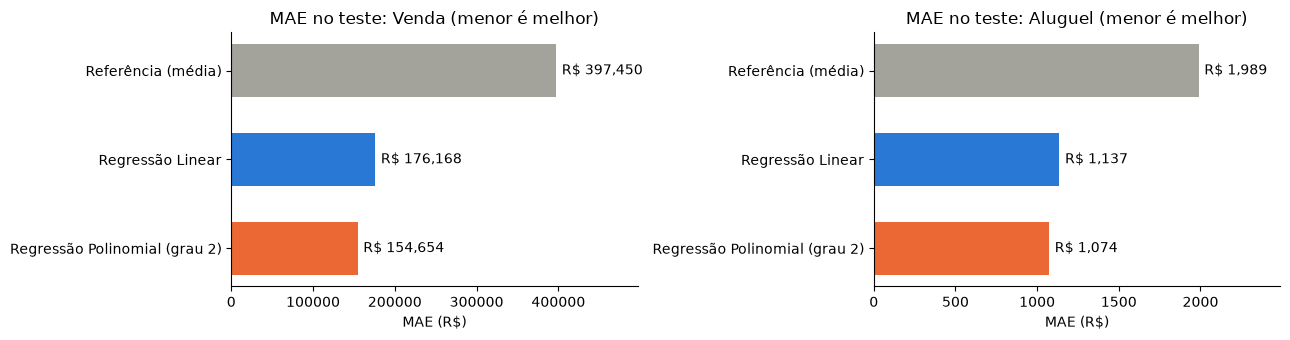

In [12]:
# Uma cor fixa para cada modelo, usada em todos os gráficos
cores = {
    "Referência (média)": "#a3a29b",
    "Regressão Linear": "#2a78d6",
    "Regressão Polinomial (grau 2)": "#eb6834",
}

# Venda e aluguel em gráficos separados, porque os preços têm escalas muito diferentes
fig, eixos = plt.subplots(1, 2, figsize=(13, 3.5))

for eixo, t, tipo in zip(eixos, [tabela_venda, tabela_aluguel], ["Venda", "Aluguel"]):
    barras = eixo.barh(t["Modelo"], t["MAE"], color=[cores[m] for m in t["Modelo"]], height=0.6)
    eixo.bar_label(barras, labels=[f"R$ {v:,.0f}" for v in t["MAE"]], padding=4)
    eixo.set_title(f"MAE no teste: {tipo} (menor é melhor)")
    eixo.set_xlabel("MAE (R$)")
    eixo.margins(x=0.25)
    eixo.invert_yaxis()
    eixo.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

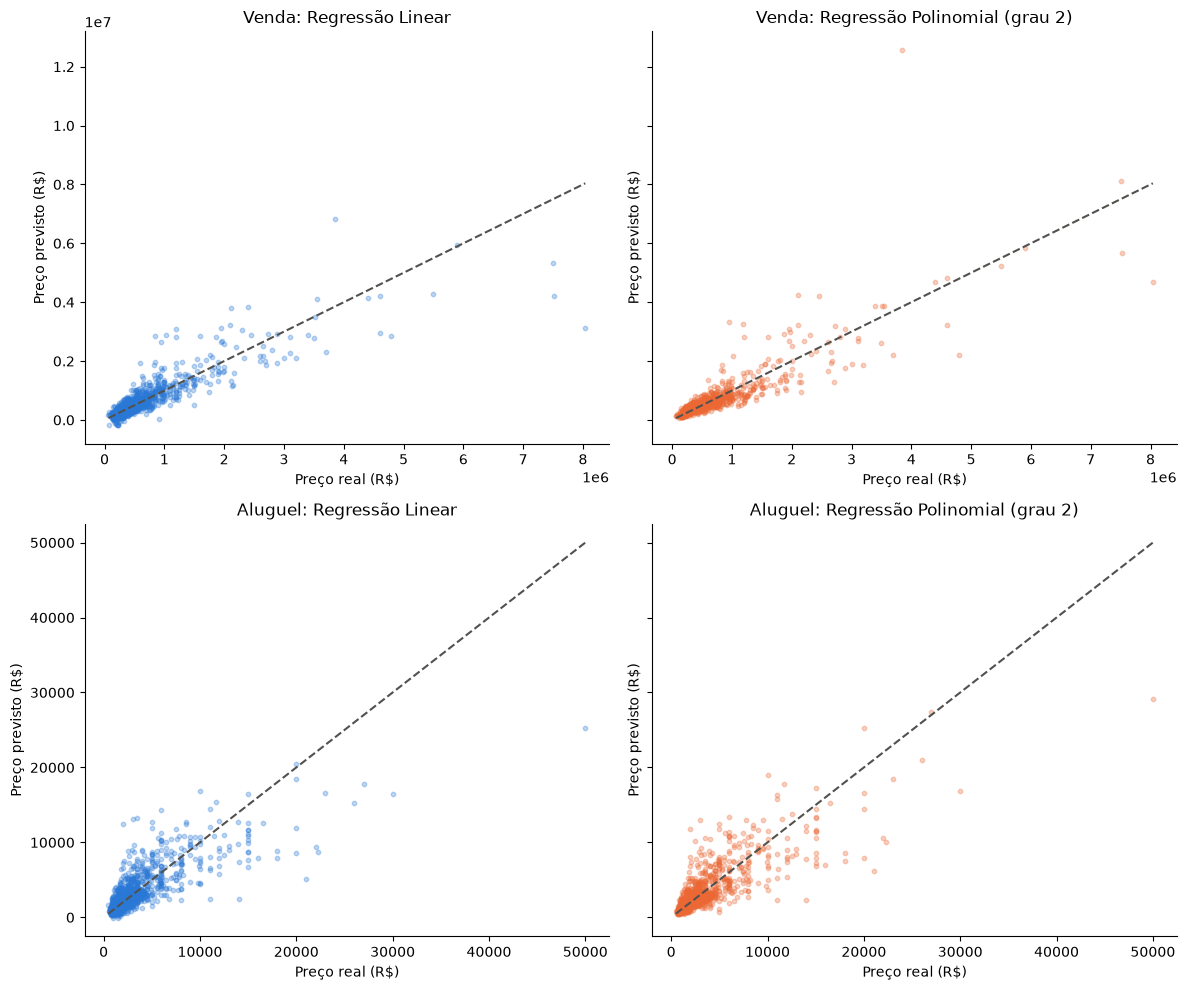

In [13]:
# Preço real x preço previsto: quanto mais perto da linha tracejada, melhor
# (os dois gráficos de cada linha usam a mesma escala, para dar para comparar os modelos)
fig, eixos = plt.subplots(2, 2, figsize=(12, 10), sharex="row", sharey="row")

graficos = [
    ("Venda", "Regressão Linear", y_teste_venda, prev_linear_venda),
    ("Venda", "Regressão Polinomial (grau 2)", y_teste_venda, prev_poli_venda),
    ("Aluguel", "Regressão Linear", y_teste_aluguel, prev_linear_aluguel),
    ("Aluguel", "Regressão Polinomial (grau 2)", y_teste_aluguel, prev_poli_aluguel),
]

for eixo, (tipo, nome, y_real, y_prev) in zip(eixos.flatten(), graficos):
    eixo.scatter(y_real, y_prev, alpha=0.3, s=10, color=cores[nome])
    eixo.plot([y_real.min(), y_real.max()], [y_real.min(), y_real.max()],
              color="#52514e", linestyle="--", linewidth=1.5)
    eixo.set_title(f"{tipo}: {nome}")
    eixo.set_xlabel("Preço real (R$)")
    eixo.set_ylabel("Preço previsto (R$)")
    eixo.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### 8.4 Onde os modelos erram

In [14]:
# 1) Previsões de preço negativo (impossíveis na vida real)
print("Previsões negativas na venda:   Linear =", (prev_linear_venda < 0).sum(),
      "| Polinomial =", (prev_poli_venda < 0).sum())
print("Previsões negativas no aluguel: Linear =", (prev_linear_aluguel < 0).sum(),
      "| Polinomial =", (prev_poli_aluguel < 0).sum())

# 2) Erro nos imóveis comuns x nos imóveis caros (venda)
erro_linear = (y_teste_venda - prev_linear_venda).abs()
erro_poli = (y_teste_venda - prev_poli_venda).abs()
caros = y_teste_venda > 1_000_000

print()
print(f"Venda, imóveis até R$ 1 milhão ({(~caros).sum()} imóveis): "
      f"MAE Linear = R$ {erro_linear[~caros].mean():,.0f} | MAE Polinomial = R$ {erro_poli[~caros].mean():,.0f}")
print(f"Venda, imóveis acima de R$ 1 milhão ({caros.sum()} imóveis): "
      f"MAE Linear = R$ {erro_linear[caros].mean():,.0f} | MAE Polinomial = R$ {erro_poli[caros].mean():,.0f}")

# 3) O maior erro da regressão polinomial na venda
i = erro_poli.to_numpy().argmax()
print()
print("Maior erro da Polinomial na venda:")
print(f"  Tamanho: {X_teste_venda['Size'].iloc[i]} m² (maior imóvel do treino: {X_treino_venda['Size'].max()} m²)")
print(f"  Preço real: R$ {y_teste_venda.iloc[i]:,.0f} | Preço previsto: R$ {prev_poli_venda[i]:,.0f}")
rmse_sem_ele = np.sqrt(np.mean(np.delete(erro_poli.to_numpy(), i) ** 2))
print(f"  RMSE da Polinomial sem esse imóvel: R$ {rmse_sem_ele:,.0f}")

Previsões negativas na venda:   Linear = 14 | Polinomial = 0
Previsões negativas no aluguel: Linear = 2 | Polinomial = 0

Venda, imóveis até R$ 1 milhão (1051 imóveis): MAE Linear = R$ 129,479 | MAE Polinomial = R$ 95,213
Venda, imóveis acima de R$ 1 milhão (138 imóveis): MAE Linear = R$ 531,749 | MAE Polinomial = R$ 607,349

Maior erro da Polinomial na venda:
  Tamanho: 620 m² (maior imóvel do treino: 420 m²)
  Preço real: R$ 3,850,000 | Preço previsto: R$ 12,563,399
  RMSE da Polinomial sem esse imóvel: R$ 292,784


## 9. Discussão dos resultados

Resumo calculado direto da tabela de resultados:

In [15]:
for tipo, t, y_teste in [("Venda", tabela_venda, y_teste_venda),
                         ("Aluguel", tabela_aluguel, y_teste_aluguel)]:
    mae_referencia = t[t["Modelo"] == "Referência (média)"]["MAE"].iloc[0]
    print(f"{tipo.upper()} (preço médio no teste: R$ {y_teste.mean():,.0f})")

    for _, linha in t[t["Modelo"] != "Referência (média)"].iterrows():
        print(f"  {linha['Modelo']}: "
              f"MAE = {linha['MAE'] / y_teste.mean() * 100:.0f}% do preço médio | "
              f"R² = {linha['R²']:.2f} | "
              f"erra {(1 - linha['MAE'] / mae_referencia) * 100:.0f}% menos que chutar a média")
    print()

VENDA (preço médio no teste: R$ 599,674)
  Regressão Linear: MAE = 29% do preço médio | R² = 0.75 | erra 56% menos que chutar a média
  Regressão Polinomial (grau 2): MAE = 26% do preço médio | R² = 0.69 | erra 61% menos que chutar a média

ALUGUEL (preço médio no teste: R$ 3,092)
  Regressão Linear: MAE = 37% do preço médio | R² = 0.63 | erra 43% menos que chutar a média
  Regressão Polinomial (grau 2): MAE = 35% do preço médio | R² = 0.66 | erra 46% menos que chutar a média



### Os modelos aprenderam alguma coisa?

Sim. O chute da média erra em média **R\$ 397 mil** na venda e **R\$ 1.989** no aluguel, com R² igual a 0. Os dois
algoritmos reduzem esse erro em **56% a 61% na venda** e **43% a 46% no aluguel**, com R² entre **0,63 e 0,75**: os
modelos explicam cerca de dois terços da variação do preço. As variáveis escolhidas no TDE 01 (tamanho, condomínio,
localização etc.) realmente ajudam a prever o preço.

### Aluguel: a Regressão Polinomial é melhor em todas as métricas

No aluguel, a Polinomial tem MAE menor (R\$ 1.074 contra R\$ 1.137), RMSE menor e R² maior (0,66 contra 0,63).
O R² de treino (0,65) e o de teste (0,66) são praticamente iguais, então **não há overfitting**. As combinações
entre variáveis que a Polinomial cria (por exemplo, tamanho × localização) ajudam a explicar o valor do aluguel.

### Venda: o melhor modelo depende da métrica

- Pelo **MAE**, a Polinomial é melhor: R\$ 155 mil contra R\$ 176 mil. Nos imóveis de até R\$ 1 milhão, que são
  quase 90% do teste, a diferença é ainda maior: cerca de R\$ 95 mil contra R\$ 129 mil.
- Pelo **RMSE e pelo R²**, a Linear é melhor: R² de 0,75 contra 0,69.

O motivo aparece na seção 8.4: a Polinomial errou feio em **um único imóvel**. Um apartamento de **620 m²**, maior que
qualquer imóvel do treino (o maior tinha 420 m²), custa R\$ 3,85 milhões e foi previsto em **R\$ 12,6 milhões** (o
ponto isolado no topo do gráfico). Como o RMSE e o R² elevam os erros ao quadrado, esse único erro pesa muito: sem
ele, o RMSE da Polinomial cairia de R\$ 387 mil para R\$ 293 mil.

Isso acontece porque a Polinomial usa termos como Size², que crescem muito rápido. Dentro da faixa de tamanhos que
o modelo viu no treino a curva funciona bem, mas fora dela (**extrapolação**) a curva "dispara". A tabela treino × teste também mostra **sinal de overfitting** na venda: R² de 0,83 no
treino e 0,69 no teste. Já a Linear generaliza bem (0,72 no treino e 0,75 no teste).

Resumindo: na venda, a Polinomial acerta melhor o imóvel comum, mas é menos confiável nos extremos. Controlar esse
comportamento é justamente o objetivo da regularização, na próxima etapa.

### A Regressão Linear prevê preços negativos

A Linear previu preço **negativo** para 14 imóveis de venda e 2 de aluguel, o que é impossível. Como o modelo é uma
reta, para imóveis pequenos e baratos a previsão pode passar para baixo de zero. A Polinomial não teve nenhuma
previsão negativa.

### Por que o RMSE é bem maior que o MAE?

Na venda, o RMSE é cerca de **2 vezes o MAE** (Linear: R\$ 346 mil contra R\$ 176 mil). O RMSE eleva os erros ao
quadrado antes da média, então poucos erros muito grandes aumentam muito o seu valor. A seção 8.4 mostra de onde vêm
esses erros: nos imóveis de venda acima de R\$ 1 milhão (cerca de 12% do teste), os dois modelos erram em média
**mais de R\$ 500 mil**, contra cerca de R\$ 100 mil nos demais.

Isso confirma o que vimos nos histogramas do TDE 01: o preço tem **assimetria positiva**, com uma cauda longa de
imóveis caros, que são poucos no treino e difíceis de prever.

### Venda x Aluguel

Os valores de MAE não podem ser comparados direto (centenas de milhares de reais na venda e milhares no aluguel).
Comparando o erro em porcentagem do preço médio, a venda erra **26% a 29%** e o aluguel **35% a 37%**, e o R² do
aluguel também é menor. Ou seja, com estas variáveis **o aluguel é mais difícil de prever**. Uma hipótese é que o
valor do aluguel depende mais de fatores que não estão no dataset, como estado de conservação, andar e vista.

### Limitações do baseline

- O preço tem distribuição assimétrica, com poucos imóveis muito caros, onde os dois modelos erram muito.
- As variáveis estão em escalas muito diferentes (m², reais, graus de latitude) e não foram normalizadas.
- O grau 2 foi escolhido sem testar outros valores, e a Polinomial mostrou overfitting na venda.
- A Regressão Linear prevê preços negativos.
- Usamos só uma divisão treino/teste, sem validação cruzada.
- O distrito não foi usado como variável (só latitude e longitude).

### Próximos passos (etapa de otimização)

1. **Regularização (Ridge e Lasso)**, conteúdo visto em sala, para controlar os pesos da Polinomial e reduzir o overfitting;
2. **normalizar as variáveis** (`StandardScaler`), o que também é necessário para a regularização funcionar bem;
3. **testar outros graus** do polinômio com validação cruzada;
4. **aplicar log no preço**, para reduzir o efeito da cauda longa e evitar previsões negativas;
5. **tratar os outliers**;
6. **incluir o distrito** com one-hot encoding.

**Metas para a próxima etapa** (superar o melhor resultado deste baseline em cada métrica):

| | MAE | R² |
|---|---|---|
| Venda | abaixo de R\$ 154.654 | acima de 0,75 |
| Aluguel | abaixo de R\$ 1.074 | acima de 0,66 |

## 10. Conclusão

- Treinamos dois algoritmos vistos em sala, **Regressão Linear** e **Regressão Polinomial (grau 2)**, sem
  otimizações, para prever o preço de venda e de aluguel de imóveis em São Paulo.
- Avaliamos os modelos com **MAE, MSE, RMSE e R²** nos dados de teste e comparamos com um chute da média.
- Os dois algoritmos explicam cerca de dois terços da variação do preço e erram bem menos que o chute da média.
- No **aluguel**, a Polinomial foi melhor em todas as métricas. Na **venda**, ela teve o menor MAE, mas um erro
  muito grande em um imóvel extremo e sinal de overfitting deixaram a Linear com R² maior.
- Os dois modelos ainda erram muito nos imóveis de alto padrão. As tabelas da seção 8 são o **baseline** do projeto:
  na próxima etapa, cada otimização precisa superar esses números.